# Isolation Forest

Implementación desde cero del algoritmo Isolation Forest para detección de anomalías (outliers).

---

## ¿Cuál es el objetivo de Isolation Forest?

Imagina que estás en una fiesta con 100 personas. La mayoría están agrupadas conversando en el centro del salón, pero hay una persona sola en una esquina lejana. Si quisieras **aislar** a esa persona del resto, bastaría con poner una sola barrera. En cambio, aislar a alguien del grupo central requeriría muchas barreras.

**Isolation Forest** usa exactamente esta idea: las **anomalías son más fáciles de aislar** que los puntos normales. En lugar de definir qué es "normal" y buscar lo que no encaja (como hacen otros métodos), Isolation Forest directamente intenta aislar cada punto y mide **cuánto esfuerzo cuesta**.

### ¿Qué es una anomalía?

Una anomalía (outlier) es un punto que es **diferente** de la mayoría. Ejemplos:
- Una transacción de 50,000 cuando el promedio es 200 → fraude bancario
- Un servidor con 99% de uso de CPU cuando lo normal es 30% → fallo del sistema
- Un paciente con valores de laboratorio extremos → posible enfermedad rara

### ¿Por qué Isolation Forest es especial?

| Método tradicional | Isolation Forest |
|---|---|
| Define "normalidad" y busca desviaciones | Directamente aísla puntos |
| Necesita calcular distancias (costoso) | Solo hace particiones aleatorias (rápido) |
| Asume distribución de los datos | No asume nada |
| Complejidad $O(n^2)$ o más | Complejidad $O(n \log n)$ |
| Modela lo normal (mayoría) | Modela lo anómalo (minoría) |

### La idea clave: profundidad del árbol

Isolation Forest construye **árboles binarios aleatorios** (llamados Isolation Trees o iTrees):

1. Selecciona una **feature aleatoria**
2. Selecciona un **punto de corte aleatorio** entre el mín y máx de esa feature
3. Divide los datos en dos grupos
4. Repite recursivamente

**Observación clave**:
- Las **anomalías** quedan aisladas en **pocas divisiones** (cerca de la raíz) → **camino corto**
- Los puntos **normales** necesitan **muchas divisiones** para separarse → **camino largo**

La **longitud promedio del camino** en múltiples árboles nos da el **puntaje de anomalía**.

---

## Un ejemplo sencillo

Veamos cómo un punto anómalo es más fácil de aislar con particiones aleatorias.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

np.random.seed(42)

# Datos: un cluster normal + 1 anomalía
X_normal = np.random.randn(20, 2) * 0.5 + np.array([3, 3])
X_anomalia = np.array([[8.0, 8.0]])  # Punto anómalo lejano
X_ejemplo = np.vstack([X_normal, X_anomalia])

etiquetas = ['Normal'] * 20 + ['Anomalía']

print("Datos del ejemplo:")
print(f"  Puntos normales: {len(X_normal)} (centrados en [3, 3])")
print(f"  Anomalía: 1 punto en {X_anomalia[0]}")
print(f"\n{'Punto':<10} {'x1':<8} {'x2':<8} {'Tipo'}")
print("-" * 35)
for i in [0, 1, 2, 19, 20]:
    tipo = etiquetas[i]
    marker = '⚠️' if tipo == 'Anomalía' else '  '
    print(f"x_{i+1:<7} {X_ejemplo[i,0]:<8.2f} {X_ejemplo[i,1]:<8.2f} {tipo} {marker}")
print("  ...")

Datos del ejemplo:
  Puntos normales: 20 (centrados en [3, 3])
  Anomalía: 1 punto en [8. 8.]

Punto      x1       x2       Tipo
-----------------------------------
x_1       3.25     2.93     Normal   
x_2       3.32     3.76     Normal   
x_3       2.88     2.88     Normal   
x_20      2.34     3.10     Normal   
x_21      8.00     8.00     Anomalía ⚠️
  ...


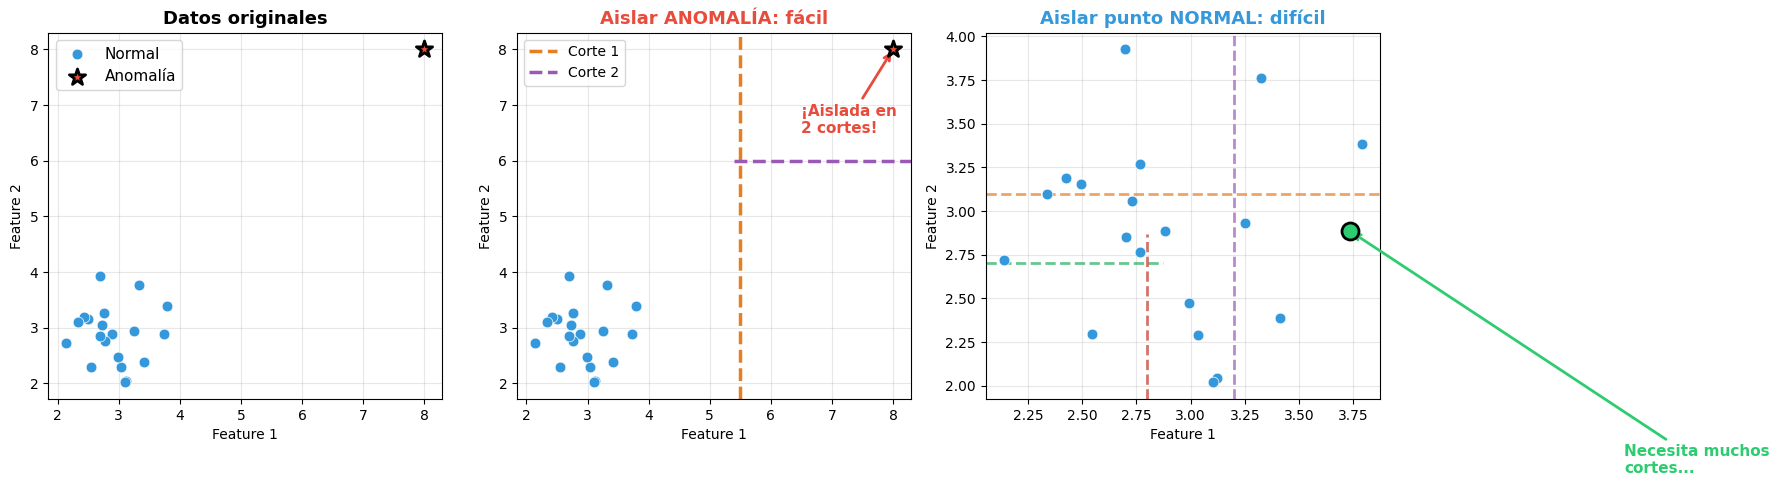

Intuición clave:
  → Anomalías: caminos CORTOS en el árbol (fáciles de aislar)
  → Puntos normales: caminos LARGOS en el árbol (difíciles de aislar)


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Datos originales
ax = axes[0]
ax.scatter(X_normal[:, 0], X_normal[:, 1], c='#3498db', s=60, edgecolors='white',
           linewidths=0.5, label='Normal', zorder=5)
ax.scatter(X_anomalia[:, 0], X_anomalia[:, 1], c='#e74c3c', s=150, edgecolors='black',
           linewidths=2, marker='*', label='Anomalía', zorder=6)
ax.set_title('Datos originales', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')

# Panel 2: Aislar la anomalía (pocos cortes)
ax = axes[1]
ax.scatter(X_normal[:, 0], X_normal[:, 1], c='#3498db', s=60, edgecolors='white',
           linewidths=0.5, zorder=5)
ax.scatter(X_anomalia[:, 0], X_anomalia[:, 1], c='#e74c3c', s=150, edgecolors='black',
           linewidths=2, marker='*', zorder=6)

# Simular 2 cortes para aislar la anomalía
ax.axvline(x=5.5, color='#e67e22', linewidth=2.5, linestyle='--', label='Corte 1')
ax.axhline(y=6.0, color='#9b59b6', linewidth=2.5, linestyle='--', xmin=0.55, label='Corte 2')
ax.annotate('¡Aislada en\n2 cortes!', xy=(8, 8), xytext=(6.5, 6.5),
            fontsize=11, fontweight='bold', color='#e74c3c',
            arrowprops=dict(arrowstyle='->', color='#e74c3c', lw=2))

ax.set_title('Aislar ANOMALÍA: fácil', fontsize=13, fontweight='bold', color='#e74c3c')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')

# Panel 3: Aislar un punto normal (muchos cortes)
ax = axes[2]
punto_normal_idx = 10
ax.scatter(X_normal[:, 0], X_normal[:, 1], c='#3498db', s=60, edgecolors='white',
           linewidths=0.5, zorder=5)
ax.scatter(X_normal[punto_normal_idx, 0], X_normal[punto_normal_idx, 1],
           c='#2ecc71', s=150, edgecolors='black', linewidths=2, marker='o', zorder=6)

# Simular muchos cortes para aislar un punto normal
ax.axhline(y=3.1, color='#e67e22', linewidth=2, linestyle='--', alpha=0.7)
ax.axvline(x=3.2, color='#9b59b6', linewidth=2, linestyle='--', alpha=0.7)
ax.axhline(y=2.7, color='#27ae60', linewidth=2, linestyle='--', alpha=0.7, xmin=0.0, xmax=0.45)
ax.axvline(x=2.8, color='#c0392b', linewidth=2, linestyle='--', alpha=0.7, ymin=0.0, ymax=0.45)
ax.annotate('Necesita muchos\ncortes...', xy=(X_normal[punto_normal_idx, 0], X_normal[punto_normal_idx, 1]),
            xytext=(5, 1.5), fontsize=11, fontweight='bold', color='#2ecc71',
            arrowprops=dict(arrowstyle='->', color='#2ecc71', lw=2))

ax.set_title('Aislar punto NORMAL: difícil', fontsize=13, fontweight='bold', color='#3498db')
ax.grid(True, alpha=0.3)
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')

plt.tight_layout()
plt.show()

print("Intuición clave:")
print("  → Anomalías: caminos CORTOS en el árbol (fáciles de aislar)")
print("  → Puntos normales: caminos LARGOS en el árbol (difíciles de aislar)")

---

Pero ¿cómo traducimos esta intuición en un algoritmo concreto? ¿Y cómo convertimos la "longitud del camino" en un puntaje de anomalía entre 0 y 1?

---

## Demostración Matemática

### Paso 1: Construcción de un Isolation Tree (iTree)

Un iTree es un árbol binario aleatorio construido así:

**Algoritmo `iTree(X, altura_actual, límite_altura)`:**
1. Si `|X| ≤ 1` o `altura_actual ≥ límite_altura`: crear nodo hoja con `tamaño = |X|`
2. Si no:
   - Elegir una feature $q$ aleatoriamente de $\{1, 2, ..., d\}$
   - Elegir un punto de corte $p$ uniformemente entre $\min(X_q)$ y $\max(X_q)$
   - Dividir: $X_{izq} = \{x \in X : x_q < p\}$, $X_{der} = \{x \in X : x_q \geq p\}$
   - Retornar nodo interno con:
     - `izquierda = iTree(X_izq, altura_actual + 1, límite_altura)`
     - `derecha = iTree(X_der, altura_actual + 1, límite_altura)`

El **límite de altura** se fija en $\lceil \log_2(\psi) \rceil$ donde $\psi$ es el tamaño de la submuestra (típicamente 256). Esto es suficiente porque las anomalías tienen caminos cortos y no necesitamos árboles profundos.

### Paso 2: Longitud del camino (Path Length)

Para un punto $x$, su **longitud de camino** $h(x)$ en un iTree es el número de aristas desde la raíz hasta la hoja donde termina.

Si el punto llega a un nodo hoja que contiene $n$ puntos (porque se alcanzó el límite de altura), le sumamos un **ajuste** $c(n)$ que estima cuántas divisiones más serían necesarias.

### Paso 3: Factor de normalización $c(n)$

Para normalizar la longitud del camino, usamos la **longitud promedio de búsqueda en un BST** (Binary Search Tree) como referencia:

$$c(n) = \begin{cases} 2H(n-1) - \frac{2(n-1)}{n} & \text{si } n > 2 \\ 1 & \text{si } n = 2 \\ 0 & \text{si } n \leq 1 \end{cases}$$

donde $H(k) = \ln(k) + \gamma$ es el número armónico y $\gamma \approx 0.5772$ es la constante de Euler-Mascheroni.

**¿Por qué un BST?** Un BST es el análogo determinista de un iTree. En un BST con $n$ elementos, la búsqueda promedio cuesta $O(\log n)$. Esto nos da una referencia de qué tan "profundo" esperamos que sea un camino en datos normales.

### Paso 4: Puntaje de anomalía

Dado un bosque de $T$ árboles, la longitud promedio del camino para un punto $x$ es:

$$E[h(x)] = \frac{1}{T}\sum_{t=1}^{T} h_t(x)$$

El **puntaje de anomalía** se define como:

$$s(x, \psi) = 2^{-\frac{E[h(x)]}{c(\psi)}}$$

donde $\psi$ es el tamaño de la submuestra.

**Interpretación del puntaje:**

| $E[h(x)]$ | $s(x)$ | Interpretación |
|---|---|---|
| $E[h(x)] \to 0$ | $s \to 1$ | Camino muy corto → **anomalía** |
| $E[h(x)] = c(\psi)$ | $s = 0.5$ | Camino promedio → **indefinido** |
| $E[h(x)] \to \infty$ | $s \to 0$ | Camino muy largo → **normal** |

Desglose de la fórmula:
- Dividimos por $c(\psi)$ para normalizar: comparamos contra la profundidad esperada
- Usamos $2^{-x}$ para mapear a $[0, 1]$: cuando $x = 0 \Rightarrow 2^0 = 1$, cuando $x \to \infty \Rightarrow 2^{-\infty} = 0$

### Paso 5: Decisión de anomalía

Típicamente, un punto se clasifica como anomalía si:

$$s(x) > \text{umbral}$$

El umbral puede ser fijo (ej: 0.5) o determinado por la **tasa de contaminación** esperada (porcentaje de anomalías en los datos).

### Resumen del algoritmo completo

**Entrenamiento:**
1. Para $t = 1, ..., T$:
   - Tomar una submuestra aleatoria de tamaño $\psi$ de los datos
   - Construir un iTree con esta submuestra

**Predicción:**
1. Para cada punto $x$, recorrer cada iTree y obtener $h_t(x)$
2. Calcular $E[h(x)] = \frac{1}{T}\sum h_t(x)$
3. Calcular $s(x) = 2^{-E[h(x)]/c(\psi)}$
4. Si $s(x) >$ umbral → **anomalía**

---

## Visualización: ¿Cómo un iTree aísla puntos?

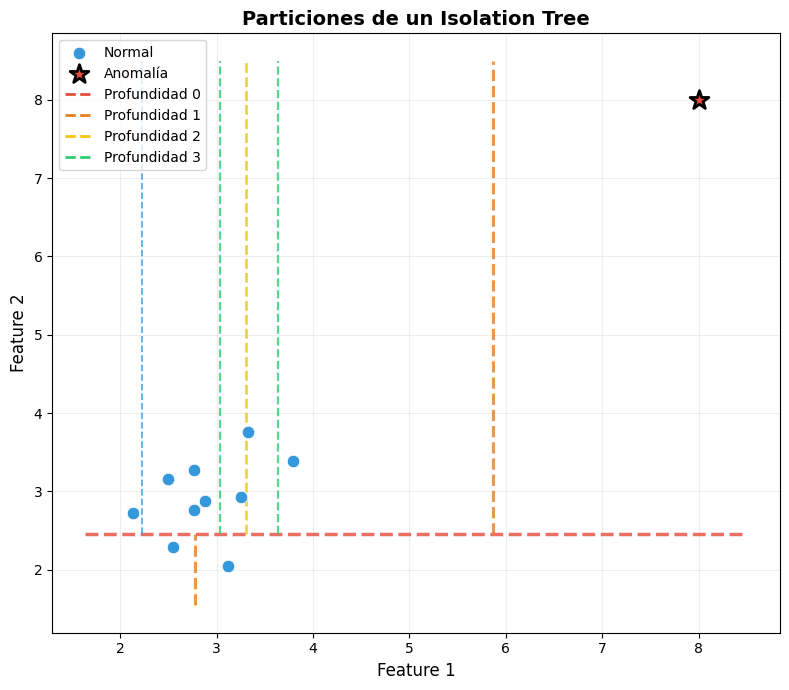

La anomalía (★) queda aislada rápidamente con pocos cortes,
mientras que los puntos normales (●) necesitan cortes más profundos.


In [3]:
# Visualizar las particiones de un iTree
np.random.seed(42)

# Datos simples
X_vis = np.vstack([X_normal[:10], X_anomalia])
n_vis = len(X_vis)

# Construir un iTree manualmente y registrar los cortes
def construir_itree_visual(X, profundidad=0, max_prof=4, x_min=None, x_max=None, y_min=None, y_max=None):
    """Construye un iTree y devuelve los cortes para visualización."""
    cortes = []

    if x_min is None:
        x_min, y_min = X[:, 0].min() - 0.5, X[:, 1].min() - 0.5
        x_max, y_max = X[:, 0].max() + 0.5, X[:, 1].max() + 0.5

    if len(X) <= 1 or profundidad >= max_prof:
        return cortes

    np.random.seed(profundidad * 100 + len(X))
    feature = np.random.randint(0, 2)
    valor = np.random.uniform(X[:, feature].min(), X[:, feature].max())

    cortes.append((feature, valor, profundidad, x_min, x_max, y_min, y_max))

    mask_izq = X[:, feature] < valor
    mask_der = ~mask_izq

    if feature == 0:  # corte vertical
        cortes += construir_itree_visual(X[mask_izq], profundidad+1, max_prof, x_min, valor, y_min, y_max)
        cortes += construir_itree_visual(X[mask_der], profundidad+1, max_prof, valor, x_max, y_min, y_max)
    else:  # corte horizontal
        cortes += construir_itree_visual(X[mask_izq], profundidad+1, max_prof, x_min, x_max, y_min, valor)
        cortes += construir_itree_visual(X[mask_der], profundidad+1, max_prof, x_min, x_max, valor, y_max)

    return cortes

cortes = construir_itree_visual(X_vis, max_prof=5)

# Visualizar
colores_prof = ['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#3498db', '#9b59b6']

fig, ax = plt.subplots(1, 1, figsize=(8, 7))

# Puntos
ax.scatter(X_normal[:10, 0], X_normal[:10, 1], c='#3498db', s=80, edgecolors='white',
           linewidths=0.5, label='Normal', zorder=5)
ax.scatter(X_anomalia[:, 0], X_anomalia[:, 1], c='#e74c3c', s=200, edgecolors='black',
           linewidths=2, marker='*', label='Anomalía', zorder=6)

# Cortes
for feature, valor, prof, xmin, xmax, ymin, ymax in cortes:
    color = colores_prof[min(prof, len(colores_prof)-1)]
    if feature == 0:  # vertical
        ax.plot([valor, valor], [ymin, ymax], color=color, linewidth=2.5-prof*0.3,
                linestyle='--', alpha=0.8)
    else:  # horizontal
        ax.plot([xmin, xmax], [valor, valor], color=color, linewidth=2.5-prof*0.3,
                linestyle='--', alpha=0.8)

# Leyenda de profundidad
for p in range(min(4, len(colores_prof))):
    ax.plot([], [], color=colores_prof[p], linewidth=2, linestyle='--', label=f'Profundidad {p}')

ax.set_title('Particiones de un Isolation Tree', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper left')
ax.grid(True, alpha=0.2)
ax.set_xlabel('Feature 1', fontsize=12); ax.set_ylabel('Feature 2', fontsize=12)

plt.tight_layout()
plt.show()

print("La anomalía (★) queda aislada rápidamente con pocos cortes,")
print("mientras que los puntos normales (●) necesitan cortes más profundos.")

---

## Ejemplo Numérico Paso a Paso

Trabajemos con 8 puntos en 1D para entender cada cálculo.

DATOS DE EJEMPLO
Punto    Valor      Tipo
------------------------------
x_1     2.0        Normal 
x_2     2.5        Normal 
x_3     3.0        Normal 
x_4     3.5        Normal 
x_5     4.0        Normal 
x_6     4.5        Normal 
x_7     5.0        Normal 
x_8     20.0       Anomalía ⚠️


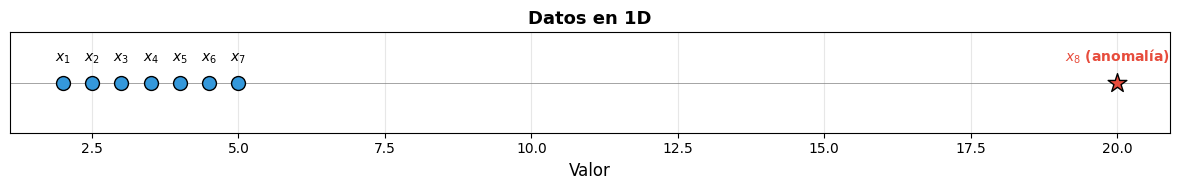

In [4]:
# 8 puntos en 1D: 7 normales + 1 anomalía
X_num = np.array([[2.0], [2.5], [3.0], [3.5], [4.0], [4.5], [5.0], [20.0]])
n_num = len(X_num)
labels_num = ['Normal']*7 + ['Anomalía']

print("="*55)
print("DATOS DE EJEMPLO")
print("="*55)
print(f"{'Punto':<8} {'Valor':<10} {'Tipo'}")
print("-" * 30)
for i in range(n_num):
    marca = '⚠️' if labels_num[i] == 'Anomalía' else ''
    print(f"x_{i+1:<5} {X_num[i,0]:<10.1f} {labels_num[i]} {marca}")

# Visualizar
fig, ax = plt.subplots(1, 1, figsize=(12, 2))
for i in range(7):
    ax.scatter(X_num[i, 0], 0, c='#3498db', s=100, edgecolors='black', zorder=5)
    ax.annotate(f'$x_{i+1}$', (X_num[i,0], 0), textcoords="offset points", xytext=(0, 15),
               ha='center', fontsize=10)
ax.scatter(X_num[7, 0], 0, c='#e74c3c', s=200, edgecolors='black', marker='*', zorder=6)
ax.annotate('$x_8$ (anomalía)', (X_num[7,0], 0), textcoords="offset points", xytext=(0, 15),
           ha='center', fontsize=10, color='#e74c3c', fontweight='bold')
ax.axhline(y=0, color='gray', linewidth=0.5)
ax.set_yticks([])
ax.set_xlabel('Valor', fontsize=12)
ax.set_title('Datos en 1D', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

In [5]:
print("="*55)
print("PASO 1: Construir un Isolation Tree")
print("="*55)
print("\nComo tenemos 1D, siempre seleccionamos la feature 0.")
print("Solo cambia el punto de corte aleatorio.\n")

np.random.seed(42)

def itree_manual(X, prof=0, nombre="Raíz"):
    """Construye un iTree imprimiendo cada paso."""
    indent = "  " * prof

    if len(X) <= 1:
        print(f"{indent}[HOJA] → {len(X)} punto(s), profundidad = {prof}")
        return prof

    # Feature 0 (única dimensión)
    vmin, vmax = X[:, 0].min(), X[:, 0].max()

    if vmin == vmax:
        print(f"{indent}[HOJA] → {len(X)} puntos iguales, profundidad = {prof}")
        return prof

    corte = np.random.uniform(vmin, vmax)

    izq = X[X[:, 0] < corte]
    der = X[X[:, 0] >= corte]

    print(f"{indent}Nodo (prof={prof}): datos={[f'{v:.1f}' for v in X[:,0]]}")
    print(f"{indent}  Corte: x < {corte:.2f}")
    print(f"{indent}  Izquierda ({len(izq)}): {[f'{v:.1f}' for v in izq[:,0]]}")
    print(f"{indent}  Derecha ({len(der)}): {[f'{v:.1f}' for v in der[:,0]]}")

    profundidades = []
    if len(izq) > 0:
        profundidades.extend([itree_manual(izq, prof+1, "Izq")])
    if len(der) > 0:
        profundidades.extend([itree_manual(der, prof+1, "Der")])

    return profundidades

print("Árbol 1 (semilla=42):")
print("-" * 50)
_ = itree_manual(X_num)

PASO 1: Construir un Isolation Tree

Como tenemos 1D, siempre seleccionamos la feature 0.
Solo cambia el punto de corte aleatorio.

Árbol 1 (semilla=42):
--------------------------------------------------
Nodo (prof=0): datos=['2.0', '2.5', '3.0', '3.5', '4.0', '4.5', '5.0', '20.0']
  Corte: x < 8.74
  Izquierda (7): ['2.0', '2.5', '3.0', '3.5', '4.0', '4.5', '5.0']
  Derecha (1): ['20.0']
  Nodo (prof=1): datos=['2.0', '2.5', '3.0', '3.5', '4.0', '4.5', '5.0']
    Corte: x < 4.85
    Izquierda (6): ['2.0', '2.5', '3.0', '3.5', '4.0', '4.5']
    Derecha (1): ['5.0']
    Nodo (prof=2): datos=['2.0', '2.5', '3.0', '3.5', '4.0', '4.5']
      Corte: x < 3.83
      Izquierda (4): ['2.0', '2.5', '3.0', '3.5']
      Derecha (2): ['4.0', '4.5']
      Nodo (prof=3): datos=['2.0', '2.5', '3.0', '3.5']
        Corte: x < 2.90
        Izquierda (2): ['2.0', '2.5']
        Derecha (2): ['3.0', '3.5']
        Nodo (prof=4): datos=['2.0', '2.5']
          Corte: x < 2.08
          Izquierda (1): ['2.

In [6]:
print("="*55)
print("PASO 2: Calcular longitud de camino h(x) para cada punto")
print("="*55)

# Construir varios árboles y medir caminos
class NodoSimple:
    def __init__(self):
        self.es_hoja = False
        self.feature = None
        self.corte = None
        self.izquierda = None
        self.derecha = None
        self.tamano = 0

def construir_itree_simple(X, prof=0, max_prof=10):
    nodo = NodoSimple()

    if len(X) <= 1 or prof >= max_prof:
        nodo.es_hoja = True
        nodo.tamano = len(X)
        return nodo

    n_features = X.shape[1]
    nodo.feature = np.random.randint(0, n_features)
    vmin = X[:, nodo.feature].min()
    vmax = X[:, nodo.feature].max()

    if vmin == vmax:
        nodo.es_hoja = True
        nodo.tamano = len(X)
        return nodo

    nodo.corte = np.random.uniform(vmin, vmax)
    mask = X[:, nodo.feature] < nodo.corte
    nodo.izquierda = construir_itree_simple(X[mask], prof+1, max_prof)
    nodo.derecha = construir_itree_simple(X[~mask], prof+1, max_prof)

    return nodo

def path_length(x, nodo, prof=0):
    """Longitud del camino de un punto en el árbol."""
    if nodo.es_hoja:
        # Ajuste c(n) para nodos hoja con múltiples puntos
        return prof + c_factor(nodo.tamano)

    if x[nodo.feature] < nodo.corte:
        return path_length(x, nodo.izquierda, prof+1)
    else:
        return path_length(x, nodo.derecha, prof+1)

def c_factor(n):
    """Factor de ajuste c(n): longitud promedio de búsqueda en BST."""
    if n <= 1:
        return 0
    if n == 2:
        return 1
    euler = 0.5772156649
    return 2 * (np.log(n - 1) + euler) - 2 * (n - 1) / n

# Construir T=10 árboles
T = 10
arboles = []
for t in range(T):
    np.random.seed(t)
    arboles.append(construir_itree_simple(X_num))

# Calcular longitud de camino en cada árbol
print(f"\nLongitudes de camino h(x) en {T} árboles:\n")
header = f"{'Punto':<8}"
for t in range(T):
    header += f"{'T'+str(t+1):<6}"
header += f"{'E[h(x)]':<10} {'Tipo'}"
print(header)
print("-" * 85)

E_h = np.zeros(n_num)
for i in range(n_num):
    caminos = []
    linea = f"x_{i+1:<5} "
    for t in range(T):
        h = path_length(X_num[i], arboles[t])
        caminos.append(h)
        linea += f"{h:<6.1f}"
    E_h[i] = np.mean(caminos)
    linea += f"{E_h[i]:<10.2f} {labels_num[i]}"
    print(linea)

print(f"\nObservación: x_8 (anomalía) tiene E[h(x)] = {E_h[7]:.2f}")
print(f"Los puntos normales tienen E[h(x)] entre {E_h[:7].min():.2f} y {E_h[:7].max():.2f}")
print("→ La anomalía tiene caminos MUCHO más cortos")

PASO 2: Calcular longitud de camino h(x) para cada punto

Longitudes de camino h(x) en 10 árboles:

Punto   T1    T2    T3    T4    T5    T6    T7    T8    T9    T10   E[h(x)]    Tipo
-------------------------------------------------------------------------------------
x_1     5.0   3.0   2.0   4.0   5.0   4.0   3.0   3.0   5.0   1.0   3.50       Normal
x_2     5.0   4.0   4.0   4.0   5.0   4.0   3.0   3.0   6.0   4.0   4.20       Normal
x_3     4.0   5.0   5.0   5.0   4.0   5.0   3.0   2.0   6.0   5.0   4.40       Normal
x_4     4.0   6.0   5.0   5.0   3.0   5.0   4.0   5.0   5.0   5.0   4.70       Normal
x_5     4.0   6.0   4.0   4.0   3.0   5.0   6.0   5.0   5.0   4.0   4.60       Normal
x_6     3.0   3.0   5.0   3.0   4.0   5.0   6.0   4.0   3.0   5.0   4.10       Normal
x_7     3.0   3.0   5.0   3.0   4.0   2.0   5.0   3.0   2.0   5.0   3.50       Normal
x_8     1.0   1.0   1.0   1.0   1.0   1.0   1.0   2.0   1.0   2.0   1.20       Anomalía

Observación: x_8 (anomalía) tiene E[h(x

In [7]:
print("="*55)
print("PASO 3: Calcular el factor de normalización c(ψ)")
print("="*55)

psi = n_num  # tamaño de submuestra = n en este caso
c_psi = c_factor(psi)

print(f"\nψ = {psi} (tamaño de submuestra)")
print(f"\nc(ψ) = 2·H(ψ-1) - 2·(ψ-1)/ψ")
euler = 0.5772156649
H_val = np.log(psi - 1) + euler
print(f"     = 2·(ln({psi-1}) + γ) - 2·{psi-1}/{psi}")
print(f"     = 2·({np.log(psi-1):.4f} + {euler:.4f}) - 2·{(psi-1)/psi:.4f}")
print(f"     = 2·{H_val:.4f} - {2*(psi-1)/psi:.4f}")
print(f"     = {2*H_val:.4f} - {2*(psi-1)/psi:.4f}")
print(f"     = {c_psi:.4f}")
print(f"\nEsto significa: en un BST con {psi} elementos, la búsqueda promedio toma ~{c_psi:.1f} pasos")

print(f"\n\n{'='*55}")
print("PASO 4: Calcular puntaje de anomalía s(x)")
print("="*55)
print(f"\nFórmula: s(x) = 2^(-E[h(x)] / c(ψ))")
print(f"c(ψ) = {c_psi:.4f}\n")

print(f"{'Punto':<8} {'E[h(x)]':<10} {'E[h]/c(ψ)':<12} {'s(x)':<10} {'Tipo':<12} {'¿Anomalía?'}")
print("-" * 65)
for i in range(n_num):
    ratio = E_h[i] / c_psi
    score = 2**(-ratio)
    es_anomalia = '✅ SÍ' if score > 0.5 else '❌ No'
    print(f"x_{i+1:<5} {E_h[i]:<10.2f} {ratio:<12.4f} {score:<10.4f} {labels_num[i]:<12} {es_anomalia}")

print(f"\nUmbral típico: s(x) > 0.5 → anomalía")
print(f"\n→ x_8 tiene puntaje {2**(-E_h[7]/c_psi):.4f} → detectada como ANOMALÍA")

PASO 3: Calcular el factor de normalización c(ψ)

ψ = 8 (tamaño de submuestra)

c(ψ) = 2·H(ψ-1) - 2·(ψ-1)/ψ
     = 2·(ln(7) + γ) - 2·7/8
     = 2·(1.9459 + 0.5772) - 2·0.8750
     = 2·2.5231 - 1.7500
     = 5.0463 - 1.7500
     = 3.2963

Esto significa: en un BST con 8 elementos, la búsqueda promedio toma ~3.3 pasos


PASO 4: Calcular puntaje de anomalía s(x)

Fórmula: s(x) = 2^(-E[h(x)] / c(ψ))
c(ψ) = 3.2963

Punto    E[h(x)]    E[h]/c(ψ)    s(x)       Tipo         ¿Anomalía?
-----------------------------------------------------------------
x_1     3.50       1.0618       0.4790     Normal       ❌ No
x_2     4.20       1.2742       0.4135     Normal       ❌ No
x_3     4.40       1.3348       0.3964     Normal       ❌ No
x_4     4.70       1.4259       0.3722     Normal       ❌ No
x_5     4.60       1.3955       0.3801     Normal       ❌ No
x_6     4.10       1.2438       0.4222     Normal       ❌ No
x_7     3.50       1.0618       0.4790     Normal       ❌ No
x_8     1.20       0.3640

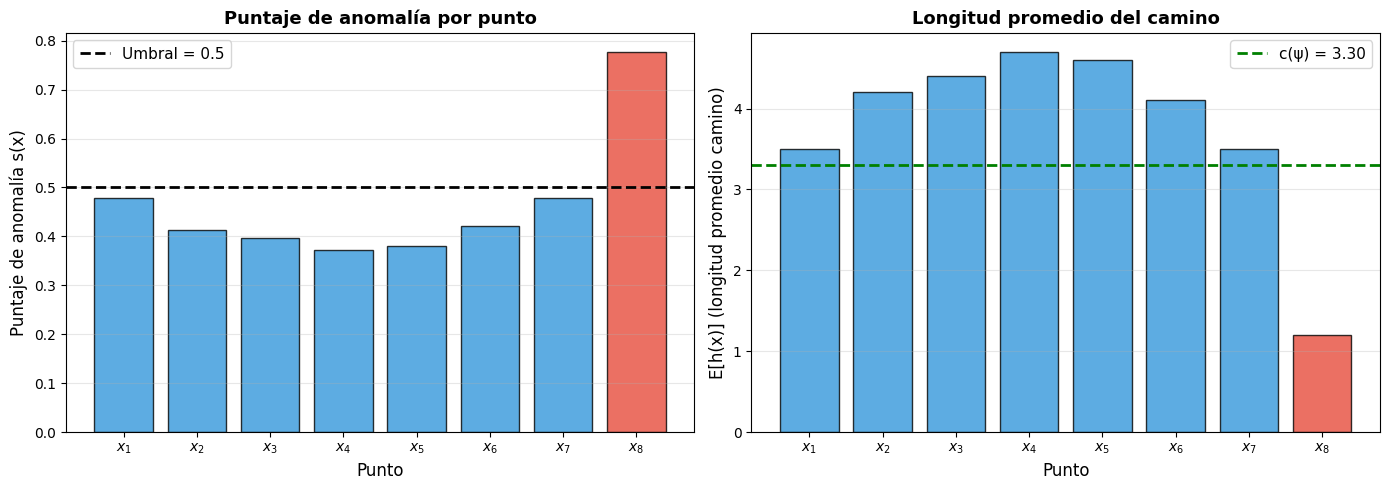

Izquierda: x_8 tiene el puntaje más alto → anomalía
Derecha: x_8 tiene el camino más corto → se aisla rápido


In [8]:
# Visualización del puntaje de anomalía
scores_num = np.array([2**(-E_h[i]/c_psi) for i in range(n_num)])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Puntajes
ax = axes[0]
colores_score = ['#e74c3c' if s > 0.5 else '#3498db' for s in scores_num]
bars = ax.bar(range(1, n_num+1), scores_num, color=colores_score, edgecolor='black', alpha=0.8)
ax.axhline(y=0.5, color='black', linestyle='--', linewidth=2, label='Umbral = 0.5')
ax.set_xlabel('Punto', fontsize=12)
ax.set_ylabel('Puntaje de anomalía s(x)', fontsize=12)
ax.set_title('Puntaje de anomalía por punto', fontsize=13, fontweight='bold')
ax.set_xticks(range(1, n_num+1))
ax.set_xticklabels([f'$x_{i+1}$' for i in range(n_num)])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

# E[h(x)] vs punto
ax = axes[1]
colores_h = ['#e74c3c' if labels_num[i] == 'Anomalía' else '#3498db' for i in range(n_num)]
ax.bar(range(1, n_num+1), E_h, color=colores_h, edgecolor='black', alpha=0.8)
ax.axhline(y=c_psi, color='green', linestyle='--', linewidth=2, label=f'c(ψ) = {c_psi:.2f}')
ax.set_xlabel('Punto', fontsize=12)
ax.set_ylabel('E[h(x)] (longitud promedio camino)', fontsize=12)
ax.set_title('Longitud promedio del camino', fontsize=13, fontweight='bold')
ax.set_xticks(range(1, n_num+1))
ax.set_xticklabels([f'$x_{i+1}$' for i in range(n_num)])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("Izquierda: x_8 tiene el puntaje más alto → anomalía")
print("Derecha: x_8 tiene el camino más corto → se aisla rápido")

---

## Implementación con Código

### Funciones

In [9]:
class NodoITree:
    """
    Nodo de un Isolation Tree.

    Puede ser:
    - Nodo interno: tiene feature, corte, hijo izquierdo y derecho
    - Nodo hoja: tiene el tamaño de la submuestra que llegó
    """
    def __init__(self, es_hoja=False, tamano=0, feature=None, corte=None,
                 izquierda=None, derecha=None):
        self.es_hoja = es_hoja
        self.tamano = tamano
        self.feature = feature
        self.corte = corte
        self.izquierda = izquierda
        self.derecha = derecha


def c_factor(n):
    """
    Calcula c(n): longitud promedio de búsqueda en un BST con n elementos.

    c(n) = 2H(n-1) - 2(n-1)/n
    donde H(k) = ln(k) + γ (número armónico, γ ≈ 0.5772)

    Parámetros
    ----------
    n : int
        Número de elementos.

    Retorna
    -------
    float
        Factor c(n).
    """
    if n <= 1:
        return 0
    if n == 2:
        return 1
    euler_mascheroni = 0.5772156649
    Hn = np.log(n - 1) + euler_mascheroni
    return 2 * Hn - 2 * (n - 1) / n


# Prueba
for n in [2, 5, 10, 50, 100, 256]:
    print(f"c({n:>3}) = {c_factor(n):.4f}")

c(  2) = 1.0000
c(  5) = 2.3270
c( 10) = 3.7489
c( 50) = 6.9781
c(100) = 8.3647
c(256) = 10.2448


In [10]:
def construir_itree(X, profundidad_actual=0, limite_profundidad=None):
    """
    Construye un Isolation Tree recursivamente.

    Parámetros
    ----------
    X : array de forma (n, d)
        Submuestra de datos.
    profundidad_actual : int
        Profundidad actual en la recursión.
    limite_profundidad : int
        Profundidad máxima del árbol.

    Retorna
    -------
    NodoITree
        Raíz del árbol construido.
    """
    n, d = X.shape

    if limite_profundidad is None:
        limite_profundidad = int(np.ceil(np.log2(max(n, 2))))

    # Condición de parada: muestra pequeña o profundidad máxima
    if n <= 1 or profundidad_actual >= limite_profundidad:
        return NodoITree(es_hoja=True, tamano=n)

    # Seleccionar feature aleatoria
    feature = np.random.randint(0, d)

    # Punto de corte aleatorio entre min y max
    vmin = X[:, feature].min()
    vmax = X[:, feature].max()

    # Si todos los valores son iguales en esta feature, es hoja
    if vmin == vmax:
        return NodoITree(es_hoja=True, tamano=n)

    corte = np.random.uniform(vmin, vmax)

    # Dividir
    mask_izq = X[:, feature] < corte
    X_izq = X[mask_izq]
    X_der = X[~mask_izq]

    # Recursión
    hijo_izq = construir_itree(X_izq, profundidad_actual + 1, limite_profundidad)
    hijo_der = construir_itree(X_der, profundidad_actual + 1, limite_profundidad)

    return NodoITree(feature=feature, corte=corte, izquierda=hijo_izq, derecha=hijo_der)


# Prueba
np.random.seed(42)
arbol_test = construir_itree(X_num)
print(f"Árbol construido con {n_num} puntos")
print(f"Raíz: feature={arbol_test.feature}, corte={arbol_test.corte:.2f}")

Árbol construido con 8 puntos
Raíz: feature=0, corte=8.74


In [11]:
def longitud_camino(x, nodo, profundidad_actual=0):
    """
    Calcula la longitud del camino de un punto x en un iTree.

    Si llega a una hoja con n > 1 puntos, suma c(n) como ajuste.

    Parámetros
    ----------
    x : array de forma (d,)
        Punto a evaluar.
    nodo : NodoITree
        Nodo actual del árbol.
    profundidad_actual : int
        Profundidad en la recursión.

    Retorna
    -------
    float
        Longitud del camino (incluyendo ajuste c(n) si aplica).
    """
    if nodo.es_hoja:
        return profundidad_actual + c_factor(nodo.tamano)

    if x[nodo.feature] < nodo.corte:
        return longitud_camino(x, nodo.izquierda, profundidad_actual + 1)
    else:
        return longitud_camino(x, nodo.derecha, profundidad_actual + 1)


# Prueba: comparar longitud de camino para normal vs anomalía
np.random.seed(42)
arbol_test = construir_itree(X_num)

for i in [0, 3, 7]:  # normal, normal, anomalía
    h = longitud_camino(X_num[i], arbol_test)
    print(f"x_{i+1} ({labels_num[i]:<8}): h(x) = {h:.2f}")

x_1 (Normal  ): h(x) = 4.85
x_4 (Normal  ): h(x) = 4.85
x_8 (Anomalía): h(x) = 1.00


In [12]:
def construir_bosque(X, n_arboles=100, tamano_submuestra=256, semilla=42):
    """
    Construye un bosque de Isolation Trees.

    Parámetros
    ----------
    X : array de forma (n, d)
        Datos de entrenamiento.
    n_arboles : int
        Número de árboles en el bosque.
    tamano_submuestra : int
        Tamaño de la submuestra para cada árbol.
    semilla : int
        Semilla para reproducibilidad.

    Retorna
    -------
    arboles : list de NodoITree
        Lista de árboles del bosque.
    """
    np.random.seed(semilla)
    n = X.shape[0]
    psi = min(tamano_submuestra, n)
    limite_prof = int(np.ceil(np.log2(max(psi, 2))))

    arboles = []
    for _ in range(n_arboles):
        # Submuestra aleatoria
        idx = np.random.choice(n, size=psi, replace=False)
        X_sub = X[idx]
        arbol = construir_itree(X_sub, limite_profundidad=limite_prof)
        arboles.append(arbol)

    return arboles


# Prueba
bosque_test = construir_bosque(X_num, n_arboles=50, tamano_submuestra=8)
print(f"Bosque construido: {len(bosque_test)} árboles")

Bosque construido: 50 árboles


In [13]:
def puntaje_anomalia(X, arboles, tamano_submuestra=256):
    """
    Calcula el puntaje de anomalía para cada punto.

    s(x) = 2^(-E[h(x)] / c(ψ))

    Parámetros
    ----------
    X : array de forma (n, d)
        Datos a evaluar.
    arboles : list de NodoITree
        Bosque de isolation trees.
    tamano_submuestra : int
        Tamaño de submuestra usado para construir los árboles.

    Retorna
    -------
    scores : array de forma (n,)
        Puntaje de anomalía para cada punto (más cercano a 1 → más anómalo).
    """
    n = X.shape[0]
    psi = min(tamano_submuestra, n)
    c_psi = c_factor(psi)

    scores = np.zeros(n)

    for i in range(n):
        # Longitud promedio del camino en todos los árboles
        h_promedio = np.mean([longitud_camino(X[i], arbol) for arbol in arboles])
        # Puntaje de anomalía
        scores[i] = 2 ** (-h_promedio / c_psi)

    return scores


# Prueba
scores_test = puntaje_anomalia(X_num, bosque_test, tamano_submuestra=8)
print("Puntajes de anomalía:")
for i in range(n_num):
    marca = ' ← ANOMALÍA' if scores_test[i] > 0.6 else ''
    print(f"  x_{i+1} ({labels_num[i]:<8}): s(x) = {scores_test[i]:.4f}{marca}")

Puntajes de anomalía:
  x_1 (Normal  ): s(x) = 0.5183
  x_2 (Normal  ): s(x) = 0.4305
  x_3 (Normal  ): s(x) = 0.4082
  x_4 (Normal  ): s(x) = 0.4020
  x_5 (Normal  ): s(x) = 0.4098
  x_6 (Normal  ): s(x) = 0.4274
  x_7 (Normal  ): s(x) = 0.4678
  x_8 (Anomalía): s(x) = 0.7803 ← ANOMALÍA


In [14]:
def predecir_anomalias(X, arboles, tamano_submuestra=256, contaminacion=0.1):
    """
    Predice qué puntos son anomalías basándose en la tasa de contaminación.

    Parámetros
    ----------
    X : array de forma (n, d)
        Datos a evaluar.
    arboles : list
        Bosque de isolation trees.
    tamano_submuestra : int
        Tamaño de submuestra.
    contaminacion : float
        Proporción esperada de anomalías (0 a 0.5).

    Retorna
    -------
    predicciones : array de forma (n,)
        1 para normal, -1 para anomalía.
    scores : array de forma (n,)
        Puntajes de anomalía.
    """
    scores = puntaje_anomalia(X, arboles, tamano_submuestra)

    # Umbral basado en contaminación
    umbral = np.percentile(scores, 100 * (1 - contaminacion))

    predicciones = np.ones(len(X), dtype=int)
    predicciones[scores >= umbral] = -1  # Anomalía

    return predicciones, scores


# Prueba
preds, scores = predecir_anomalias(X_num, bosque_test, tamano_submuestra=8, contaminacion=0.15)
print("Predicciones (contaminación=15%):")
for i in range(n_num):
    estado = 'ANOMALÍA' if preds[i] == -1 else 'Normal'
    print(f"  x_{i+1}: {estado} (score={scores[i]:.4f})")

Predicciones (contaminación=15%):
  x_1: ANOMALÍA (score=0.5183)
  x_2: Normal (score=0.4305)
  x_3: Normal (score=0.4082)
  x_4: Normal (score=0.4020)
  x_5: Normal (score=0.4098)
  x_6: Normal (score=0.4274)
  x_7: Normal (score=0.4678)
  x_8: ANOMALÍA (score=0.7803)


### Clase

In [15]:
class IsolationForest:
    """
    Isolation Forest para detección de anomalías, implementado desde cero.

    Construye un conjunto de Isolation Trees que aíslan puntos mediante
    particiones aleatorias. Las anomalías, al ser "pocas y diferentes",
    se aíslan con caminos más cortos.

    Parámetros
    ----------
    n_arboles : int, default=100
        Número de Isolation Trees en el bosque.
    tamano_submuestra : int, default=256
        Tamaño de la submuestra para construir cada árbol.
    contaminacion : float o 'auto', default='auto'
        Proporción esperada de anomalías en los datos.
        Si 'auto', usa 0.5 como umbral del puntaje.
    semilla : int, default=42
        Semilla para reproducibilidad.

    Atributos
    ---------
    arboles_ : list de NodoITree
        Árboles del bosque entrenado.
    umbral_ : float
        Umbral para clasificar anomalías.
    scores_entrenamiento_ : array
        Puntajes de anomalía de los datos de entrenamiento.
    """

    def __init__(self, n_arboles=100, tamano_submuestra=256, contaminacion='auto', semilla=42):
        self.n_arboles = n_arboles
        self.tamano_submuestra = tamano_submuestra
        self.contaminacion = contaminacion
        self.semilla = semilla

        self.arboles_ = []
        self.umbral_ = None
        self.scores_entrenamiento_ = None
        self._psi = None

    def _construir_itree(self, X, prof=0, max_prof=None):
        """Construye un Isolation Tree recursivamente."""
        n, d = X.shape

        if n <= 1 or prof >= max_prof:
            return NodoITree(es_hoja=True, tamano=n)

        feature = np.random.randint(0, d)
        vmin, vmax = X[:, feature].min(), X[:, feature].max()

        if vmin == vmax:
            return NodoITree(es_hoja=True, tamano=n)

        corte = np.random.uniform(vmin, vmax)
        mask = X[:, feature] < corte

        izq = self._construir_itree(X[mask], prof + 1, max_prof)
        der = self._construir_itree(X[~mask], prof + 1, max_prof)

        return NodoITree(feature=feature, corte=corte, izquierda=izq, derecha=der)

    def _longitud_camino(self, x, nodo, prof=0):
        """Longitud del camino de un punto en un iTree."""
        if nodo.es_hoja:
            return prof + c_factor(nodo.tamano)
        if x[nodo.feature] < nodo.corte:
            return self._longitud_camino(x, nodo.izquierda, prof + 1)
        return self._longitud_camino(x, nodo.derecha, prof + 1)

    def _puntaje(self, X):
        """Calcula puntaje de anomalía para un conjunto de datos."""
        n = X.shape[0]
        c_psi = c_factor(self._psi)
        scores = np.zeros(n)

        for i in range(n):
            h_promedio = np.mean([self._longitud_camino(X[i], arbol) for arbol in self.arboles_])
            scores[i] = 2 ** (-h_promedio / c_psi)

        return scores

    def fit(self, X):
        """
        Entrena el modelo construyendo el bosque de Isolation Trees.

        Parámetros
        ----------
        X : array de forma (n, d)
            Datos de entrenamiento.

        Retorna
        -------
        self
        """
        np.random.seed(self.semilla)
        n = X.shape[0]
        self._psi = min(self.tamano_submuestra, n)
        max_prof = int(np.ceil(np.log2(max(self._psi, 2))))

        self.arboles_ = []
        for _ in range(self.n_arboles):
            idx = np.random.choice(n, size=self._psi, replace=False)
            arbol = self._construir_itree(X[idx], max_prof=max_prof)
            self.arboles_.append(arbol)

        # Calcular puntajes y umbral
        self.scores_entrenamiento_ = self._puntaje(X)

        if self.contaminacion == 'auto':
            self.umbral_ = 0.5
        else:
            self.umbral_ = np.percentile(
                self.scores_entrenamiento_, 100 * (1 - self.contaminacion)
            )

        return self

    def predict(self, X):
        """
        Predice si cada punto es normal (1) o anomalía (-1).

        Parámetros
        ----------
        X : array de forma (n, d)
            Datos a clasificar.

        Retorna
        -------
        predicciones : array de forma (n,)
            1 para normal, -1 para anomalía.
        """
        scores = self._puntaje(X)
        predicciones = np.ones(len(X), dtype=int)
        predicciones[scores >= self.umbral_] = -1
        return predicciones

    def score_samples(self, X):
        """
        Retorna el puntaje de anomalía para cada punto.

        Valores más altos indican mayor probabilidad de ser anomalía.

        Parámetros
        ----------
        X : array de forma (n, d)

        Retorna
        -------
        scores : array de forma (n,)
        """
        return self._puntaje(X)

    def plot_anomalias(self, X, y_true=None, titulo='Isolation Forest', ax=None):
        """
        Visualiza los datos con anomalías detectadas (solo para datos 2D).

        Parámetros
        ----------
        X : array de forma (n, 2)
            Datos 2D.
        y_true : array, opcional
            Etiquetas verdaderas (1=normal, -1=anomalía).
        titulo : str
            Título del gráfico.
        ax : matplotlib axis, opcional
        """
        show = False
        if ax is None:
            fig, ax = plt.subplots(1, 1, figsize=(8, 6))
            show = True

        preds = self.predict(X)
        scores = self._puntaje(X)

        normal = preds == 1
        anomalo = preds == -1

        ax.scatter(X[normal, 0], X[normal, 1], c='#3498db', s=30, alpha=0.6,
                  edgecolors='white', linewidths=0.3, label=f'Normal ({normal.sum()})')
        ax.scatter(X[anomalo, 0], X[anomalo, 1], c='#e74c3c', s=80, alpha=0.8,
                  edgecolors='black', linewidths=1, marker='*', label=f'Anomalía ({anomalo.sum()})')

        ax.set_title(titulo, fontsize=14, fontweight='bold')
        ax.set_xlabel('Feature 1', fontsize=12)
        ax.set_ylabel('Feature 2', fontsize=12)
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3)

        if show:
            plt.tight_layout()
            plt.show()

    def plot_scores(self, X, y_true=None):
        """
        Visualiza el mapa de calor de puntajes de anomalía (solo 2D).

        Parámetros
        ----------
        X : array de forma (n, 2)
            Datos 2D.
        y_true : array, opcional
            Etiquetas verdaderas.
        """
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        # Mapa de calor de puntajes
        ax = axes[0]
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 80), np.linspace(y_min, y_max, 80))
        grid = np.c_[xx.ravel(), yy.ravel()]

        Z = self._puntaje(grid).reshape(xx.shape)

        contour = ax.contourf(xx, yy, Z, levels=20, cmap='RdYlBu_r', alpha=0.8)
        plt.colorbar(contour, ax=ax, label='Puntaje de anomalía')

        preds = self.predict(X)
        normal = preds == 1
        anomalo = preds == -1
        ax.scatter(X[normal, 0], X[normal, 1], c='white', s=20, edgecolors='black',
                  linewidths=0.5, alpha=0.7)
        ax.scatter(X[anomalo, 0], X[anomalo, 1], c='red', s=60, edgecolors='black',
                  linewidths=1, marker='*')
        ax.set_title('Mapa de puntajes de anomalía', fontsize=13, fontweight='bold')
        ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')

        # Distribución de puntajes
        ax = axes[1]
        scores = self._puntaje(X)

        if y_true is not None:
            scores_normal = scores[y_true == 1]
            scores_anomalo = scores[y_true == -1]
            ax.hist(scores_normal, bins=30, alpha=0.6, color='#3498db',
                   label='Normales (real)', density=True)
            ax.hist(scores_anomalo, bins=30, alpha=0.6, color='#e74c3c',
                   label='Anomalías (real)', density=True)
        else:
            ax.hist(scores, bins=30, alpha=0.7, color='#3498db', density=True)

        ax.axvline(x=self.umbral_, color='black', linestyle='--', linewidth=2,
                  label=f'Umbral = {self.umbral_:.3f}')
        ax.set_xlabel('Puntaje de anomalía', fontsize=12)
        ax.set_ylabel('Densidad', fontsize=12)
        ax.set_title('Distribución de puntajes', fontsize=13, fontweight='bold')
        ax.legend(fontsize=10)
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()


print("Clase IsolationForest definida correctamente ✓")

Clase IsolationForest definida correctamente ✓


---

## Experimentos

### 1. Detección de anomalías en datos sintéticos 2D

In [16]:
from sklearn.datasets import make_blobs

np.random.seed(42)

# Datos normales: un cluster
X_train_normal, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=1.0, random_state=42)

# Anomalías: puntos dispersos
n_anomalias = 30
X_anomalias = np.random.uniform(-6, 6, size=(n_anomalias, 2))

# Combinar
X_train = np.vstack([X_train_normal, X_anomalias])
y_true = np.array([1]*300 + [-1]*n_anomalias)

print(f"Datos: {len(X_train)} puntos ({len(X_train_normal)} normales + {n_anomalias} anomalías)")
print(f"Tasa de contaminación real: {n_anomalias/len(X_train):.1%}")

# Entrenar
iforest = IsolationForest(n_arboles=100, tamano_submuestra=256, contaminacion=0.1, semilla=42)
iforest.fit(X_train)

print(f"\nUmbral calculado: {iforest.umbral_:.4f}")

# Predicciones
preds = iforest.predict(X_train)
n_detectadas = np.sum(preds == -1)
print(f"Anomalías detectadas: {n_detectadas}")

# Precisión
correctas = np.sum((preds == -1) & (y_true == -1))
falsas_alarmas = np.sum((preds == -1) & (y_true == 1))
no_detectadas = np.sum((preds == 1) & (y_true == -1))
print(f"  Anomalías correctamente detectadas: {correctas}/{n_anomalias}")
print(f"  Falsas alarmas: {falsas_alarmas}")
print(f"  Anomalías no detectadas: {no_detectadas}")

Datos: 330 puntos (300 normales + 30 anomalías)
Tasa de contaminación real: 9.1%

Umbral calculado: 0.5243
Anomalías detectadas: 33
  Anomalías correctamente detectadas: 26/30
  Falsas alarmas: 7
  Anomalías no detectadas: 4


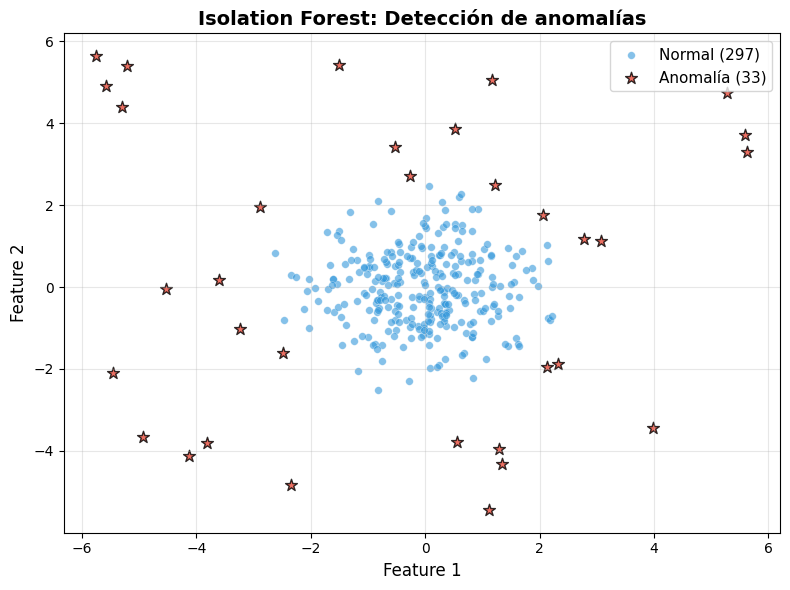

In [17]:
iforest.plot_anomalias(X_train, y_true, titulo='Isolation Forest: Detección de anomalías')

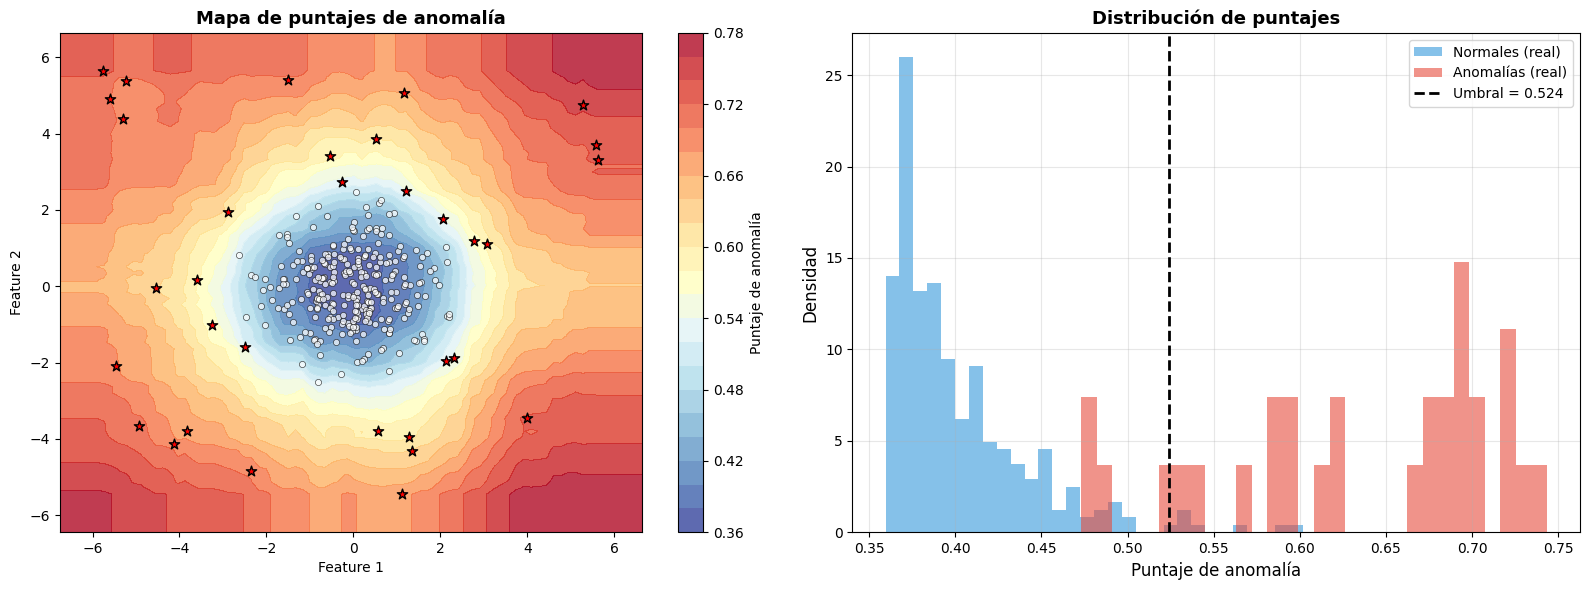

In [18]:
iforest.plot_scores(X_train, y_true)

### 2. Efecto de la contaminación

El parámetro de contaminación controla cuántos puntos se etiquetan como anomalías.

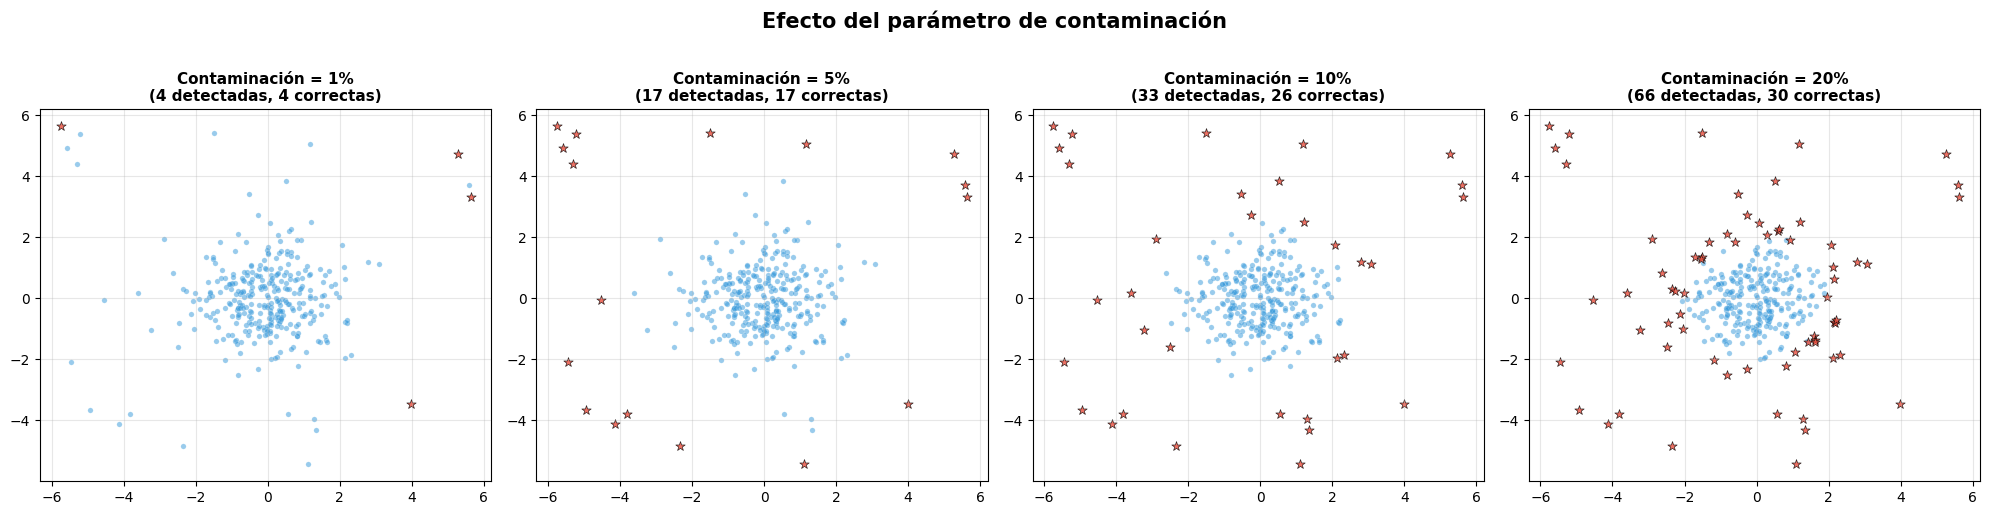

Observaciones:
• Contaminación muy baja (1%): pocas detecciones, pierde anomalías
• Contaminación correcta (~9%): buena detección
• Contaminación alta (20%): detecta todas las anomalías pero genera falsas alarmas


In [19]:
contaminaciones = [0.01, 0.05, 0.10, 0.20]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for idx, cont in enumerate(contaminaciones):
    modelo = IsolationForest(n_arboles=100, tamano_submuestra=256, contaminacion=cont, semilla=42)
    modelo.fit(X_train)

    preds = modelo.predict(X_train)
    n_det = np.sum(preds == -1)
    correctas = np.sum((preds == -1) & (y_true == -1))

    ax = axes[idx]
    normal = preds == 1
    anomalo = preds == -1

    ax.scatter(X_train[normal, 0], X_train[normal, 1], c='#3498db', s=15, alpha=0.5,
              edgecolors='white', linewidths=0.2)
    ax.scatter(X_train[anomalo, 0], X_train[anomalo, 1], c='#e74c3c', s=50, alpha=0.8,
              edgecolors='black', linewidths=0.5, marker='*')

    ax.set_title(f'Contaminación = {cont:.0%}\n({n_det} detectadas, {correctas} correctas)',
                fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.suptitle('Efecto del parámetro de contaminación', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Observaciones:")
print("• Contaminación muy baja (1%): pocas detecciones, pierde anomalías")
print("• Contaminación correcta (~9%): buena detección")
print("• Contaminación alta (20%): detecta todas las anomalías pero genera falsas alarmas")

### 3. Múltiples clusters con anomalías

Datos: 465 puntos (450 normales + 15 anomalías)


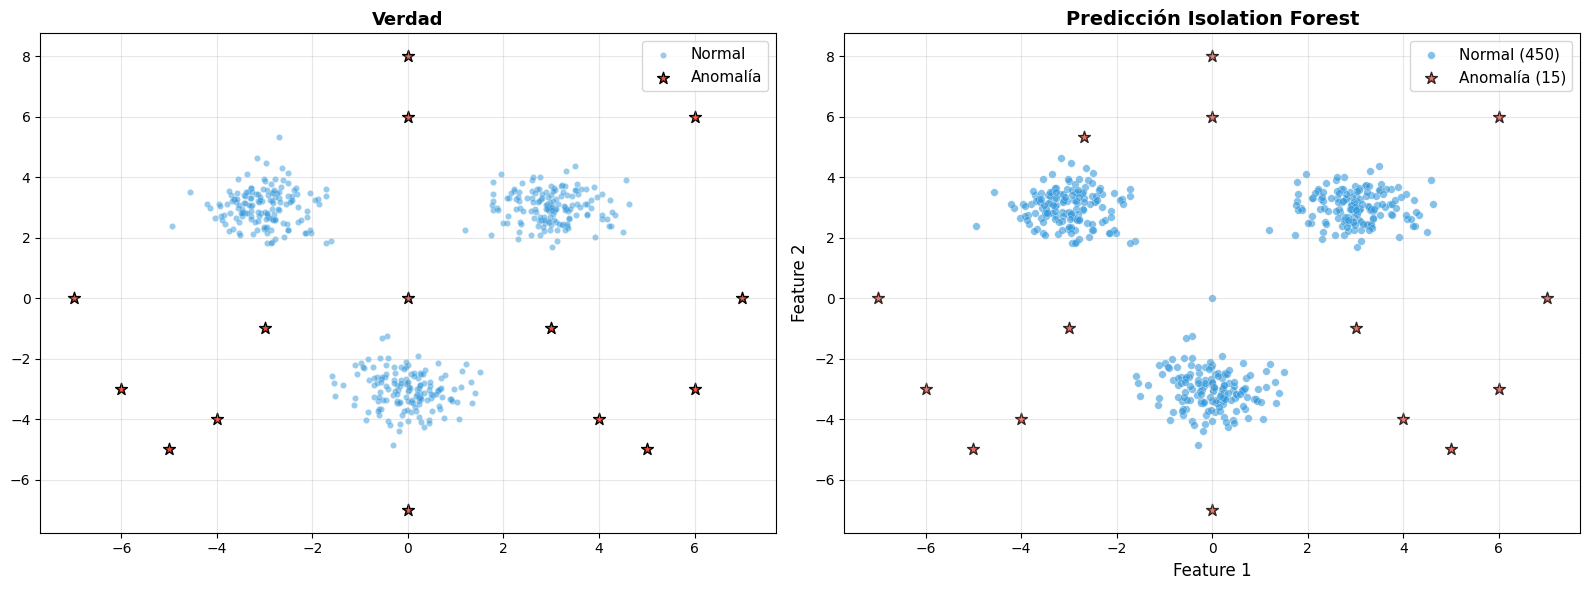


Anomalías correctamente detectadas: 14/15


In [20]:
np.random.seed(42)

# 3 clusters normales
X_c1, _ = make_blobs(n_samples=150, centers=[[-3, 3]], cluster_std=0.6, random_state=42)
X_c2, _ = make_blobs(n_samples=150, centers=[[3, 3]], cluster_std=0.6, random_state=43)
X_c3, _ = make_blobs(n_samples=150, centers=[[0, -3]], cluster_std=0.6, random_state=44)

# Anomalías entre los clusters
X_anom = np.array([
    [0, 0], [0, 6], [-6, -3], [6, -3], [-5, -5],
    [5, -5], [0, 8], [-7, 0], [7, 0], [0, -7],
    [-4, -4], [4, -4], [-3, -1], [3, -1], [6, 6],
])

X_multi = np.vstack([X_c1, X_c2, X_c3, X_anom])
y_multi = np.array([1]*450 + [-1]*len(X_anom))

print(f"Datos: {len(X_multi)} puntos (450 normales + {len(X_anom)} anomalías)")

# Entrenar
iforest_multi = IsolationForest(n_arboles=100, tamano_submuestra=256,
                                 contaminacion=len(X_anom)/len(X_multi), semilla=42)
iforest_multi.fit(X_multi)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Verdad vs predicción
ax = axes[0]
normal_true = y_multi == 1
anom_true = y_multi == -1
ax.scatter(X_multi[normal_true, 0], X_multi[normal_true, 1], c='#3498db', s=20,
          alpha=0.5, edgecolors='white', linewidths=0.2, label='Normal')
ax.scatter(X_multi[anom_true, 0], X_multi[anom_true, 1], c='#e74c3c', s=80,
          edgecolors='black', linewidths=1, marker='*', label='Anomalía')
ax.set_title('Verdad', fontsize=13, fontweight='bold')
ax.legend(fontsize=11); ax.grid(True, alpha=0.3)

iforest_multi.plot_anomalias(X_multi, titulo='Predicción Isolation Forest', ax=axes[1])

plt.tight_layout()
plt.show()

preds_multi = iforest_multi.predict(X_multi)
correctas = np.sum((preds_multi == -1) & (y_multi == -1))
print(f"\nAnomalías correctamente detectadas: {correctas}/{len(X_anom)}")

### 4. Efecto del número de árboles

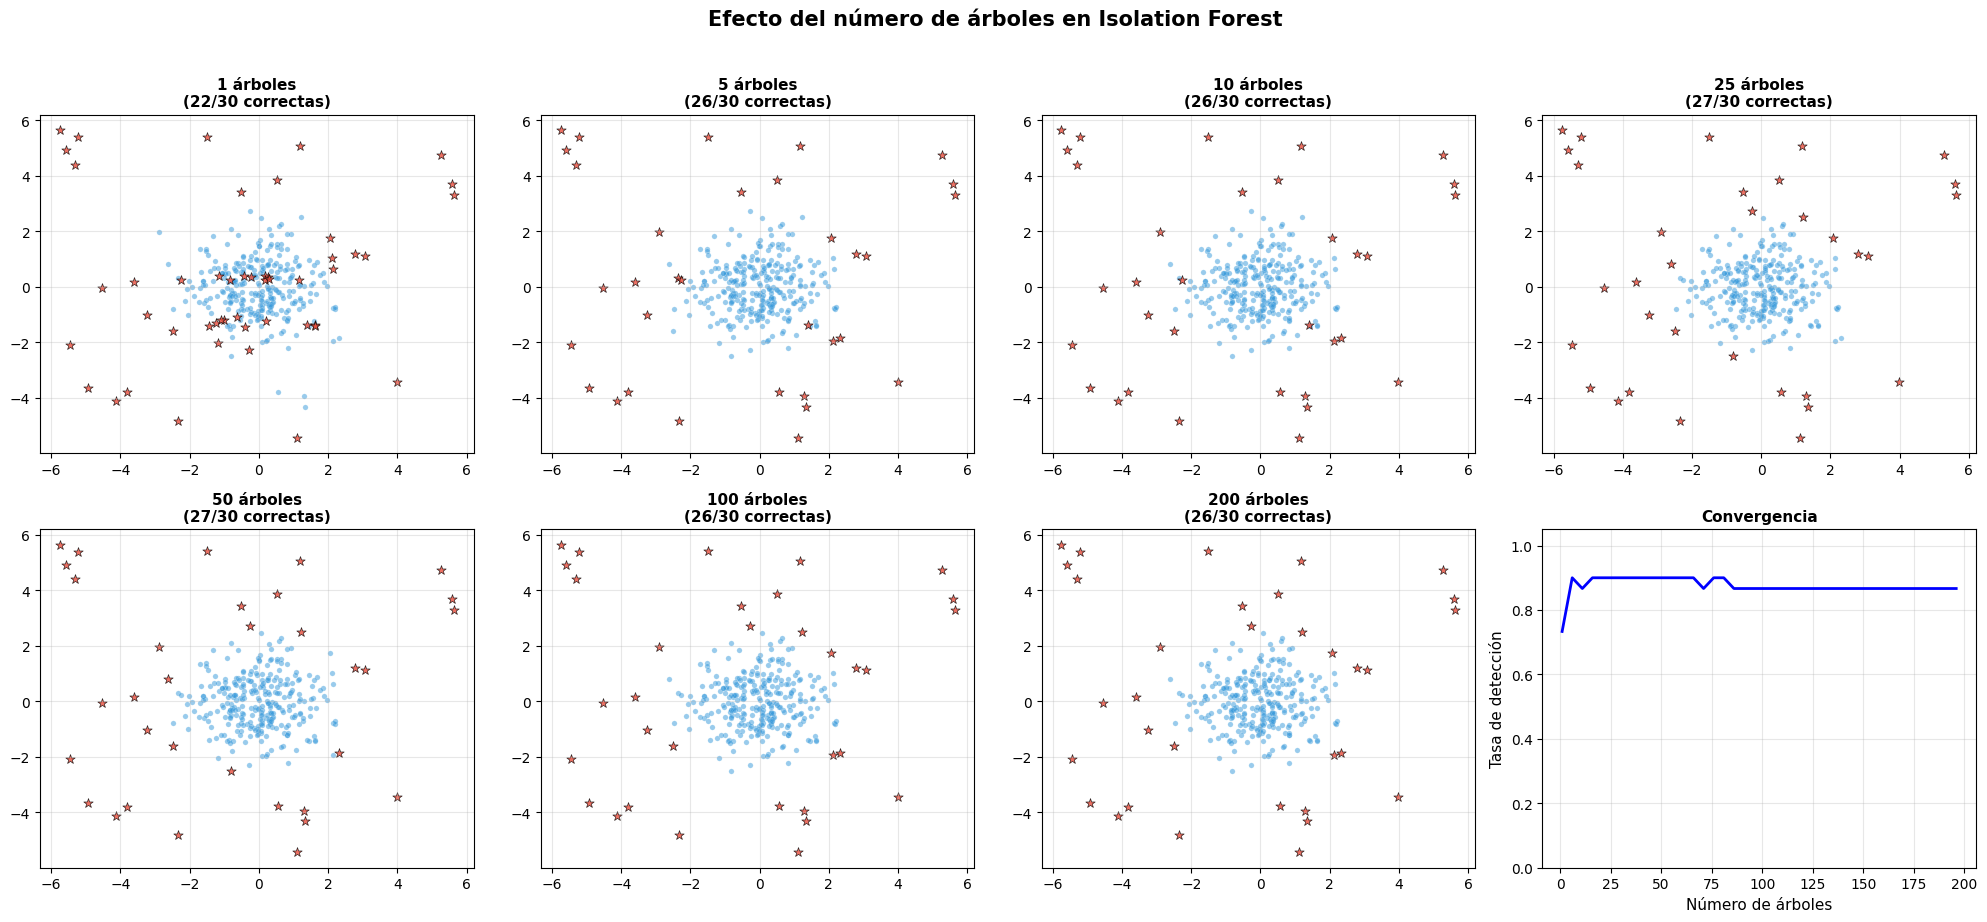

Observaciones:
• Con 1 árbol: resultados muy ruidosos e inestables
• Con 10-25 árboles: resultados aceptables
• Con 50+ árboles: resultados estables (convergencia)
• Más de 100 árboles: poco beneficio adicional


In [21]:
n_arboles_lista = [1, 5, 10, 25, 50, 100, 200]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for idx, n_t in enumerate(n_arboles_lista):
    modelo_t = IsolationForest(n_arboles=n_t, tamano_submuestra=256,
                                contaminacion=0.1, semilla=42)
    modelo_t.fit(X_train)

    preds_t = modelo_t.predict(X_train)
    scores_t = modelo_t.score_samples(X_train)
    correctas = np.sum((preds_t == -1) & (y_true == -1))

    ax = axes[idx]
    normal = preds_t == 1
    anomalo = preds_t == -1

    ax.scatter(X_train[normal, 0], X_train[normal, 1], c='#3498db', s=15, alpha=0.5,
              edgecolors='white', linewidths=0.2)
    ax.scatter(X_train[anomalo, 0], X_train[anomalo, 1], c='#e74c3c', s=50, alpha=0.8,
              edgecolors='black', linewidths=0.5, marker='*')
    ax.set_title(f'{n_t} árboles\n({correctas}/{n_anomalias} correctas)',
                fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

# Gráfico de convergencia
ax = axes[7]
precisiones = []
for n_t in range(1, 201, 5):
    m = IsolationForest(n_arboles=n_t, tamano_submuestra=256, contaminacion=0.1, semilla=42)
    m.fit(X_train)
    p = m.predict(X_train)
    correctas = np.sum((p == -1) & (y_true == -1))
    precisiones.append(correctas / n_anomalias)

ax.plot(range(1, 201, 5), precisiones, 'b-', linewidth=2)
ax.set_xlabel('Número de árboles', fontsize=11)
ax.set_ylabel('Tasa de detección', fontsize=11)
ax.set_title('Convergencia', fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.05)

plt.suptitle('Efecto del número de árboles en Isolation Forest', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Observaciones:")
print("• Con 1 árbol: resultados muy ruidosos e inestables")
print("• Con 10-25 árboles: resultados aceptables")
print("• Con 50+ árboles: resultados estables (convergencia)")
print("• Más de 100 árboles: poco beneficio adicional")

### 5. Detección de anomalías en datos reales (Iris)

Datos Iris (solo Setosa + anomalías):
  Normales: 50 muestras (4 features)
  Anomalías: 8 puntos aleatorios

Resultados:
  Anomalías detectadas correctamente: 8/8
  Falsas alarmas: 0


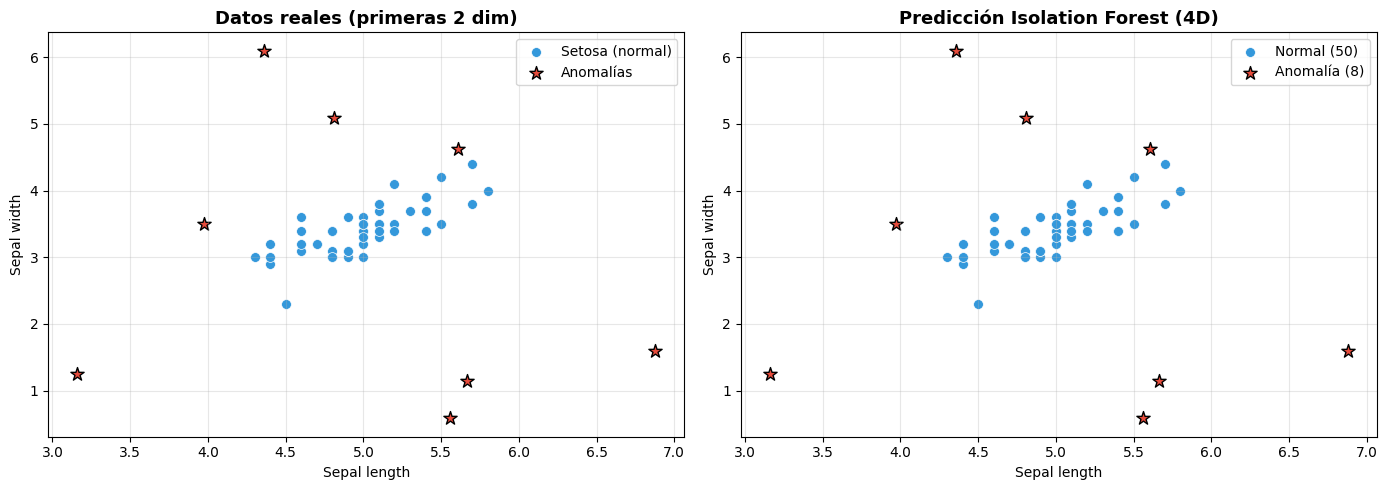


Nota: Isolation Forest trabaja en las 4 dimensiones,
aunque solo mostramos las primeras 2 en el gráfico.


In [22]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Usar solo la clase 0 (setosa) como "normal" y agregar anomalías sintéticas
X_setosa = X_iris[y_iris == 0]  # 50 muestras, 4D

# Crear anomalías: valores extremos
np.random.seed(42)
n_anom_iris = 8
X_anom_iris = np.random.uniform(
    X_setosa.min(axis=0) - 2,
    X_setosa.max(axis=0) + 2,
    size=(n_anom_iris, 4)
)

X_iris_test = np.vstack([X_setosa, X_anom_iris])
y_iris_test = np.array([1]*50 + [-1]*n_anom_iris)

print(f"Datos Iris (solo Setosa + anomalías):")
print(f"  Normales: {len(X_setosa)} muestras (4 features)")
print(f"  Anomalías: {n_anom_iris} puntos aleatorios")

# Entrenar
iforest_iris = IsolationForest(n_arboles=100, tamano_submuestra=50,
                                contaminacion=n_anom_iris/len(X_iris_test), semilla=42)
iforest_iris.fit(X_iris_test)

preds_iris = iforest_iris.predict(X_iris_test)
scores_iris = iforest_iris.score_samples(X_iris_test)

# Resultados
correctas = np.sum((preds_iris == -1) & (y_iris_test == -1))
falsas = np.sum((preds_iris == -1) & (y_iris_test == 1))
print(f"\nResultados:")
print(f"  Anomalías detectadas correctamente: {correctas}/{n_anom_iris}")
print(f"  Falsas alarmas: {falsas}")

# Visualizar en las 2 primeras dimensiones
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Datos reales
ax = axes[0]
ax.scatter(X_setosa[:, 0], X_setosa[:, 1], c='#3498db', s=50, edgecolors='white',
          linewidths=0.5, label='Setosa (normal)')
ax.scatter(X_anom_iris[:, 0], X_anom_iris[:, 1], c='#e74c3c', s=100, edgecolors='black',
          linewidths=1, marker='*', label='Anomalías')
ax.set_xlabel('Sepal length'); ax.set_ylabel('Sepal width')
ax.set_title('Datos reales (primeras 2 dim)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

# Predicciones
ax = axes[1]
normal_pred = preds_iris == 1
anom_pred = preds_iris == -1
ax.scatter(X_iris_test[normal_pred, 0], X_iris_test[normal_pred, 1], c='#3498db', s=50,
          edgecolors='white', linewidths=0.5, label=f'Normal ({normal_pred.sum()})')
ax.scatter(X_iris_test[anom_pred, 0], X_iris_test[anom_pred, 1], c='#e74c3c', s=100,
          edgecolors='black', linewidths=1, marker='*', label=f'Anomalía ({anom_pred.sum()})')
ax.set_xlabel('Sepal length'); ax.set_ylabel('Sepal width')
ax.set_title('Predicción Isolation Forest (4D)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nNota: Isolation Forest trabaja en las 4 dimensiones,")
print("aunque solo mostramos las primeras 2 en el gráfico.")

### 6. Formas complejas: anillos y lunas

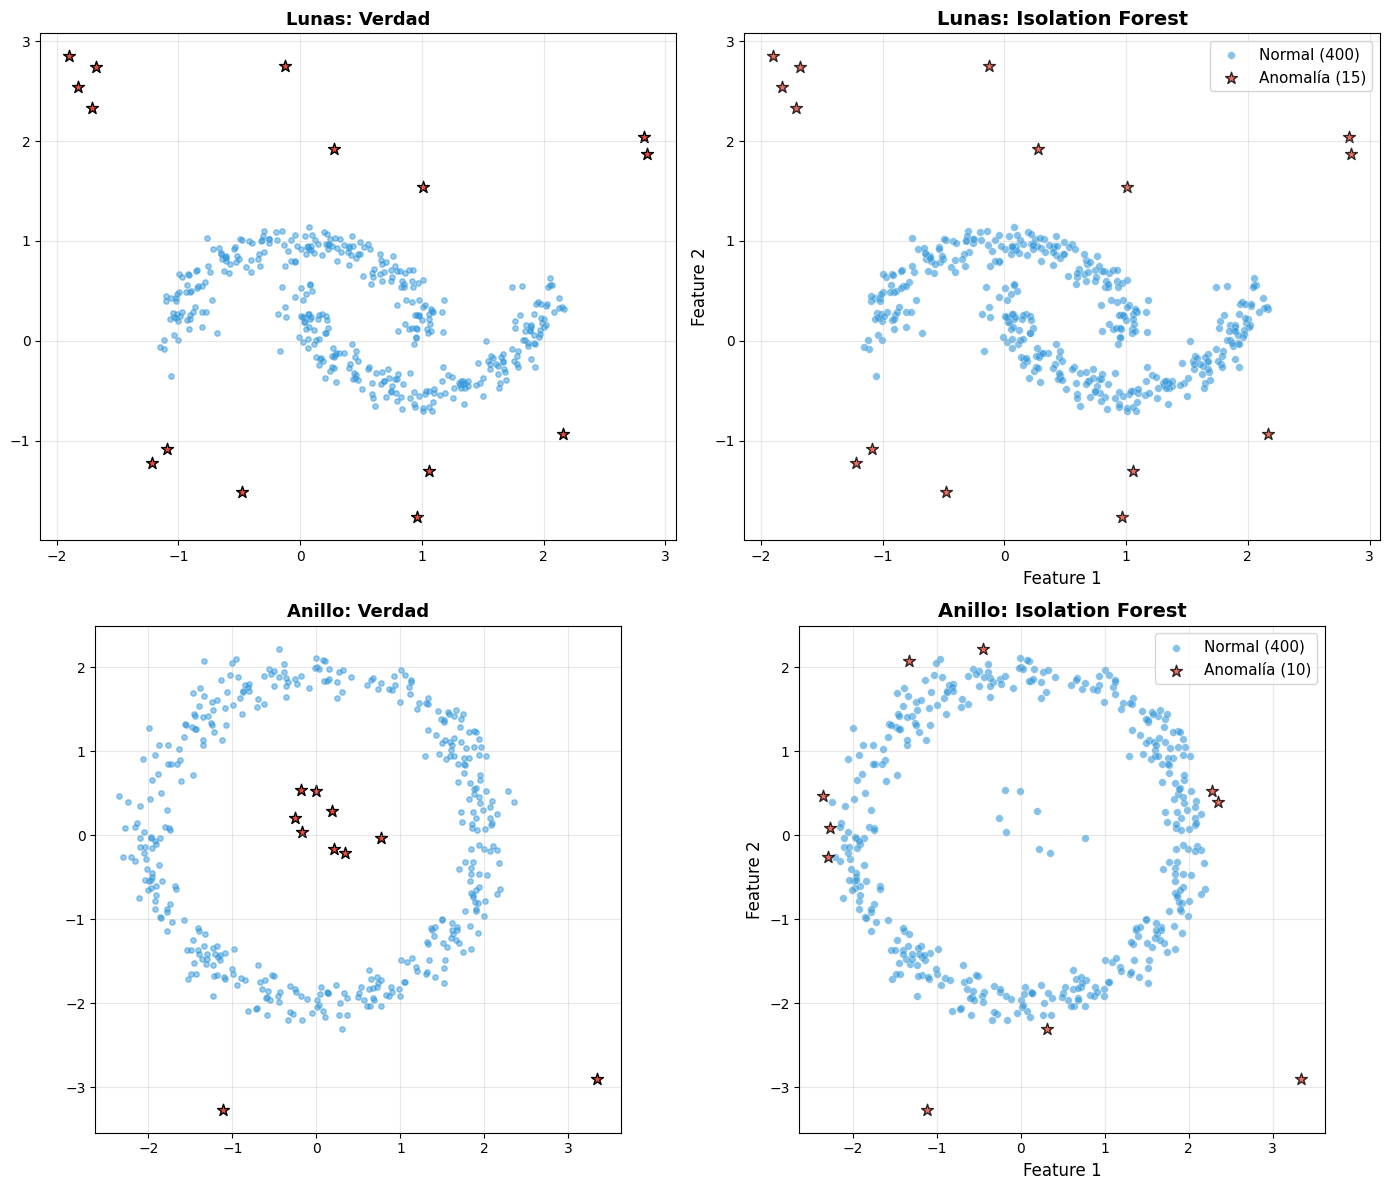

Lunas - Anomalías correctas: 15/15
Anillo - Anomalías correctas: 2/10

Isolation Forest funciona bien con formas no lineales complejas
porque no asume ninguna distribución de los datos.


In [23]:
from sklearn.datasets import make_moons

np.random.seed(42)

# Datos en forma de lunas
X_moons, _ = make_moons(n_samples=400, noise=0.1, random_state=42)

# Anomalías dispersas
X_anom_moons = np.random.uniform(-2, 3, size=(30, 2))
# Filtrar las que caen dentro de la forma normal
from scipy.spatial.distance import cdist
dist_to_moons = cdist(X_anom_moons, X_moons).min(axis=1)
X_anom_moons = X_anom_moons[dist_to_moons > 0.5][:15]

X_total_moons = np.vstack([X_moons, X_anom_moons])
y_total_moons = np.array([1]*len(X_moons) + [-1]*len(X_anom_moons))

# Datos en forma de anillo
theta = np.random.uniform(0, 2*np.pi, 400)
r = 2 + np.random.randn(400) * 0.15
X_ring = np.column_stack([r * np.cos(theta), r * np.sin(theta)])

# Anomalías en el centro y fuera
X_anom_ring = np.vstack([
    np.random.randn(8, 2) * 0.3,  # centro
    np.random.uniform(-4, 4, size=(7, 2))  # fuera
])
dist_to_ring = cdist(X_anom_ring, X_ring).min(axis=1)
X_anom_ring = X_anom_ring[dist_to_ring > 0.5][:10]

X_total_ring = np.vstack([X_ring, X_anom_ring])
y_total_ring = np.array([1]*len(X_ring) + [-1]*len(X_anom_ring))

# Entrenar y visualizar
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Lunas: verdad
ax = axes[0, 0]
ax.scatter(X_moons[:, 0], X_moons[:, 1], c='#3498db', s=15, alpha=0.5)
ax.scatter(X_anom_moons[:, 0], X_anom_moons[:, 1], c='#e74c3c', s=80, marker='*', edgecolors='black')
ax.set_title('Lunas: Verdad', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

# Lunas: predicción
iforest_moons = IsolationForest(n_arboles=100, contaminacion=len(X_anom_moons)/len(X_total_moons), semilla=42)
iforest_moons.fit(X_total_moons)
iforest_moons.plot_anomalias(X_total_moons, titulo='Lunas: Isolation Forest', ax=axes[0, 1])

# Anillo: verdad
ax = axes[1, 0]
ax.scatter(X_ring[:, 0], X_ring[:, 1], c='#3498db', s=15, alpha=0.5)
ax.scatter(X_anom_ring[:, 0], X_anom_ring[:, 1], c='#e74c3c', s=80, marker='*', edgecolors='black')
ax.set_title('Anillo: Verdad', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3); ax.set_aspect('equal')

# Anillo: predicción
iforest_ring = IsolationForest(n_arboles=100, contaminacion=len(X_anom_ring)/len(X_total_ring), semilla=42)
iforest_ring.fit(X_total_ring)
iforest_ring.plot_anomalias(X_total_ring, titulo='Anillo: Isolation Forest', ax=axes[1, 1])
axes[1, 1].set_aspect('equal')

plt.tight_layout()
plt.show()

p_m = iforest_moons.predict(X_total_moons)
p_r = iforest_ring.predict(X_total_ring)
print(f"Lunas - Anomalías correctas: {np.sum((p_m==-1) & (y_total_moons==-1))}/{len(X_anom_moons)}")
print(f"Anillo - Anomalías correctas: {np.sum((p_r==-1) & (y_total_ring==-1))}/{len(X_anom_ring)}")
print("\nIsolation Forest funciona bien con formas no lineales complejas")
print("porque no asume ninguna distribución de los datos.")

---

## Resumen

| Concepto | Descripción |
|---|---|
| **Objetivo** | Detectar anomalías (outliers) en los datos |
| **Idea clave** | Las anomalías son más fáciles de aislar con particiones aleatorias |
| **Estructura** | Bosque de Isolation Trees (árboles binarios aleatorios) |
| **Métrica** | Longitud promedio del camino $E[h(x)]$ |
| **Puntaje** | $s(x) = 2^{-E[h(x)]/c(\psi)}$, donde $c(\psi)$ normaliza |
| **Anomalía** | Puntaje cercano a 1 (caminos cortos) |
| **Normal** | Puntaje cercano a 0 (caminos largos) |
| **Hiperparámetros** | `n_arboles` (100), `tamano_submuestra` (256), `contaminacion` |
| **Complejidad** | $O(T \cdot \psi \cdot \log \psi)$ entrenamiento, $O(T \cdot \log \psi)$ predicción |
| **Ventajas** | Rápido, sin suposiciones, escala bien, maneja alta dimensionalidad |
| **Limitación** | Sensible al parámetro de contaminación, menos efectivo con anomalías en regiones densas |